# Portafolio de Estadística: Inferencia Paramétrica, Bondad de Ajuste y Predicción (LTRM)

**Enlace al Dataset original:** [https://www.umesc.usgs.gov/data_library/fisheries/fish1_query.html](https://www.umesc.usgs.gov/data_library/fisheries/fish1_query.html)  
**Dataset de trabajo:** `df_limpio.csv` *(El conjunto de datos ya se encuentra limpio, sin valores nulos ni inconsistencias de captura).*

<div align="center">
  <a href="https://www.umesc.usgs.gov/data_library/fisheries/fish1_query.html">
    <img src="https://img.shields.io/badge/-🗄️_Ir_a_la_Base_de_Datos-238636?style=for-the-badge" alt="Botón Base de Datos" />
  </a>
</div>

<div align="center">
  <a href="https://axiscrazy.github.io/Probabilidad-y-estadistica-2/index.html">
    <img src="https://img.shields.io/badge/-⬅️_Regresar_a_la_página_web-007ACC?style=for-the-badge" alt="Botón Regresar" />
  </a>
</div>

### Flujo de análisis
1. Validación de **tamaño de muestra** y **normalidad** (escala original vs. transformación $\log_{10}$).
2. **Prueba de Bondad de Ajuste ($\chi^2$)** sobre la distribución de frecuencias de las especies (`fishcode`).
3. **Prueba F para dos varianzas** entre las dos especies principales para evaluar homocedasticidad.
4. **Prueba t de Welch** para dos medias independientes con varianzas desiguales y tamaño del efecto ($d$ de Cohen).
5. **ANOVA de un factor** (con respaldo no paramétrico y Tukey HSD) para las 5 especies principales.
6. **Modelos predictivos de peso y tamaño** incorporando la especie y su relación alométrica.

In [4]:
import pandas as pd
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

df = pd.read_csv('df_limpio.csv')
df = df[(df['weight'] > 0) & (df['length'] > 0)].copy()

print(f"Total de registros listos para análisis: {df.shape[0]}")
print(f"Total de especies distintas (fishcode): {df['fishcode'].nunique()}")
df[['fishcode', 'length', 'weight']].head()

Total de registros listos para análisis: 92221
Total de especies distintas (fishcode): 100


,fishcode,length,weight
0,LMBS,174.0,75.0
1,LMBS,124.0,29.0
2,BLGL,149.0,84.0
3,BLGL,165.0,119.0
4,BLGL,151.0,82.0


### 1. Verificación y Cálculo de Tamaño de Muestra

Antes de contrastar hipótesis, comprobamos dos criterios de suficiencia muestral:
1. **Tamaño mínimo teórico ($n$):** Registros necesarios para estimar la media de $\log_{10}(\text{weight})$ con un 95% de confianza ($Z_{0.025} = 1.96$) y un margen de error ($E$) equivalente al 5% de la desviación estándar muestral:
$$ n = \left( \frac{Z_{\alpha/2} \cdot s}{E} \right)^2 $$
2. **Suficiencia por categoría:** Se seleccionan las **5 especies más abundantes** para Bondad de Ajuste y ANOVA, y las **2 más abundantes** para la prueba F y t de Welch, verificando $n_i \ge 30$ en cada grupo.

In [5]:
conteo_especies = df['fishcode'].value_counts()
top5_especies = conteo_especies.head(5).index.tolist()
top2_especies = conteo_especies.head(2).index.tolist()

df_top5 = df[df['fishcode'].isin(top5_especies)].copy()
df_top5['log_weight'] = np.log10(df_top5['weight'])
df_top5['log_length'] = np.log10(df_top5['length'])

z_crit = st.norm.ppf(0.975)
s_global = df_top5['log_weight'].std(ddof=1)
error_max = 0.05 * s_global
n_minimo = int(np.ceil((z_crit * s_global / error_max) ** 2))

resumen_muestra = df_top5.groupby('fishcode').agg(
    n=('weight', 'count'),
    media_peso_g=('weight', 'mean'),
    std_peso_g=('weight', 'std'),
    media_log_peso=('log_weight', 'mean'),
    var_log_peso=('log_weight', 'var'),
    media_tamano_mm=('length', 'mean')
).loc[top5_especies]
resumen_muestra['cumple_n_min_30'] = resumen_muestra['n'] >= 30

print(f"Tamaño mínimo teórico calculado (95% conf.): {n_minimo} registros")
print(f"Registros disponibles en Top 5 especies: {len(df_top5)}")
print(f"Suficiencia global: {'Cumple' if len(df_top5) >= n_minimo else 'No cumple'}\n")
print(resumen_muestra.round(4))

Tamaño mínimo teórico calculado (95% conf.): 1537 registros
Registros disponibles en Top 5 especies: 52832
Suficiencia global: Cumple

              n  media_peso_g  std_peso_g  media_log_peso  var_log_peso  \
fishcode                                                                  
BLGL      18848       50.7856     54.1350          1.4304        0.3169   
LMBS       9564      195.2803    345.1919          1.7188        0.4894   
CNCF       8760      536.8682    800.8155          2.2850        0.4561   
GZSD       8036       75.5887    117.3229          1.5401        0.2793   
CARP       7624     2369.2721   1609.3979          3.2188        0.2229   

          media_tamano_mm  cumple_n_min_30  
fishcode                                    
BLGL             118.4810             True  
LMBS             178.7607             True  
CNCF             324.5365             True  
GZSD             169.4017             True  
CARP             522.3642             True  


### 2. Pruebas de Normalidad (Escala Original vs. Transformación $\log_{10}$)

Las pruebas paramétricas requieren poblaciones aproximadamente normales o tamaños de muestra grandes que permitan invocar el Teorema del Límite Central. Evaluamos cada especie con la prueba $K^2$ de D'Agostino-Pearson junto con sus coeficientes de **asimetría (*skewness*)** y **curtosis**:

- $H_0$: Los pesos de la especie siguen una distribución normal.
- $H_1$: Los pesos de la especie **no** siguen una distribución normal.

Dado el enorme volumen de datos ($N$ de miles), incluso desviaciones mínimas producen $p < 0.05$. Por ello, se compara la reducción del estadístico $K^2$, la asimetría y la forma del gráfico Q-Q al aplicar $\log_{10}(\text{weight})$.

Especie     n  Asimetria_Orig  K2_Orig  Asimetria_Log10  Curtosis_Log10  K2_Log10     p_Log10
   BLGL 18848           1.926  7352.15           -0.677           0.127   1206.12 1.2401e-262
   LMBS  9564           2.462  4769.62            0.529          -0.772   1104.94 1.1639e-240
   CNCF  8760           2.716  5122.33           -0.128          -0.456    154.08  3.4744e-34
   GZSD  8036           3.227  5525.70            0.311          -0.155    133.15  1.2216e-29
   CARP  7624           1.192  1850.44           -1.905           4.763   2941.56  0.0000e+00


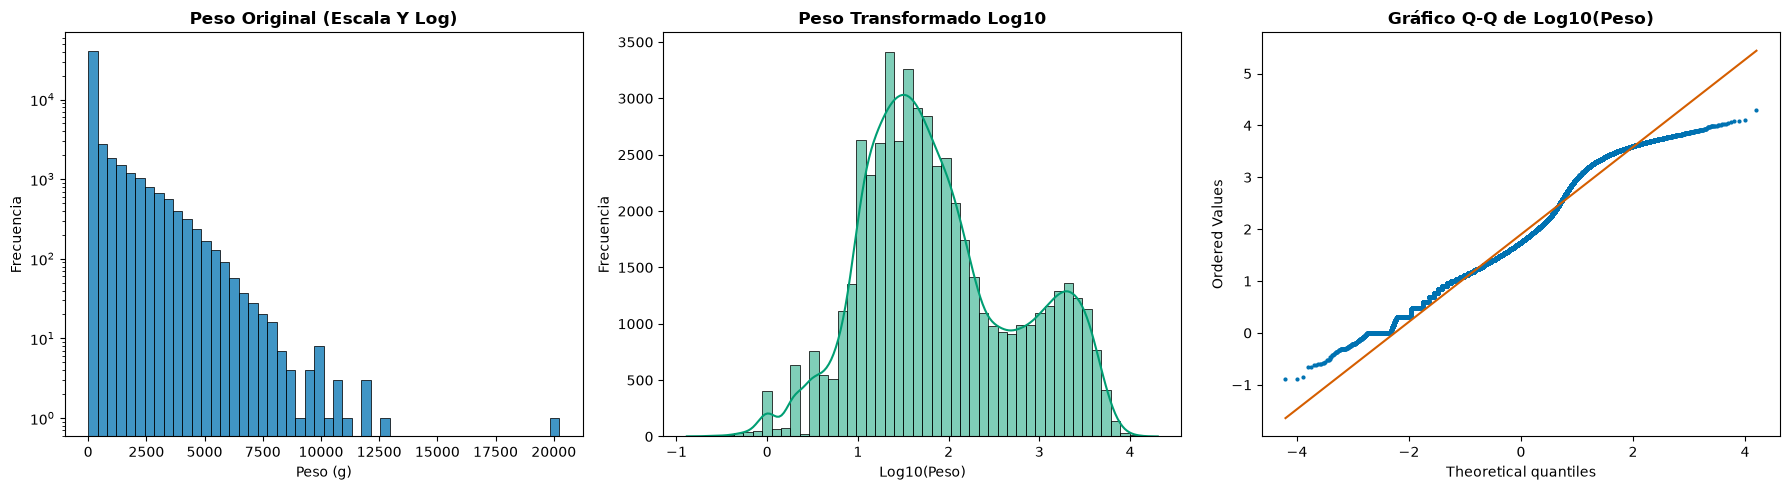

In [6]:
resultados_norm = []
for esp in top5_especies:
    d_orig = df_top5[df_top5['fishcode'] == esp]['weight']
    d_log = df_top5[df_top5['fishcode'] == esp]['log_weight']
    stat_o, p_o = st.normaltest(d_orig)
    stat_l, p_l = st.normaltest(d_log)
    resultados_norm.append({
        'Especie': esp,
        'n': len(d_orig),
        'Asimetria_Orig': round(st.skew(d_orig), 3),
        'K2_Orig': round(stat_o, 2),
        'Asimetria_Log10': round(st.skew(d_log), 3),
        'Curtosis_Log10': round(st.kurtosis(d_log), 3),
        'K2_Log10': round(stat_l, 2),
        'p_Log10': f"{p_l:.4e}"
    })

print(pd.DataFrame(resultados_norm).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df_top5['weight'], bins=50, kde=False, ax=axes[0], color='#0072B2')
axes[0].set_yscale('log')
axes[0].set_title('Peso Original (Escala Y Log)', fontweight='bold')
axes[0].set_xlabel('Peso (g)')
axes[0].set_ylabel('Frecuencia')

sns.histplot(df_top5['log_weight'], bins=50, kde=True, ax=axes[1], color='#009E73')
axes[1].set_title('Peso Transformado Log10', fontweight='bold')
axes[1].set_xlabel('Log10(Peso)')
axes[1].set_ylabel('Frecuencia')

st.probplot(df_top5['log_weight'], dist='norm', plot=axes[2])
axes[2].get_lines()[0].set_color('#0072B2')
axes[2].get_lines()[0].set_markersize(2)
axes[2].get_lines()[1].set_color('#D55E00')
axes[2].set_title('Gráfico Q-Q de Log10(Peso)', fontweight='bold')

plt.tight_layout()
plt.show()

### 3. Prueba de Bondad de Ajuste ($\chi^2$): Distribución Uniforme de Especies

Evaluamos si las capturas de las 5 especies principales se distribuyen de manera **uniforme** ($p_i = 1/k = 0.20$) en el ecosistema o si existe dominancia estadísticamente significativa de ciertas especies.

- **Paso 0 (Supuestos):** Categorías (`fishcode`) mutuamente excluyentes, capturas independientes, frecuencias observadas conocidas y verificación de que todas las frecuencias esperadas cumplan $FE_i \ge 5$.
- **Paso 1 (Hipótesis):**
  - $H_0: p_1 = p_2 = p_3 = p_4 = p_5 = 0.20$ *(Las capturas se distribuyen uniformemente entre las 5 especies).*
  - $H_1:$ Al menos una especie tiene una proporción distinta de $0.20$.
- **Paso 2 (Significancia):** $\alpha = 0.05$ (prueba de cola derecha).
- **Paso 3 (Estadístico y gl):**
$$ \chi^2 = \sum_{i=1}^{k} \frac{(FO_i - FE_i)^2}{FE_i}, \qquad FE_i = n \cdot p_i, \qquad gl = k - 1 - m $$
*(Con $k = 5$ categorías y $m = 0$ parámetros estimados de los datos, $gl = 4$).*

--- Tabla de Bondad de Ajuste Chi-Cuadrada ---
Especie    FO  p_i      FE  (FO-FE)^2/FE
   BLGL 18848  0.2 10566.4       6490.85
   LMBS  9564  0.2 10566.4         95.09
   CNCF  8760  0.2 10566.4        308.82
   GZSD  8036  0.2 10566.4        605.97
   CARP  7624  0.2 10566.4        819.36

Todas las FE >= 5: Sí
n = 52832 | k = 5 | gl = 4 | alpha = 0.05
Estadístico Chi2 calculado: 8320.0927
Valor crítico Chi2 (cola derecha): 9.4877
p-value: 0.0000e+00
Paso 5 - Decisión: Rechazar H0
Interpretación: Existe evidencia estadística de que las 5 especies NO se capturan en igual proporción; hay dominancia de especies.
Paso 6 - Posible error: Error Tipo I (concluir que la abundancia no es uniforme cuando en la población real sí lo fuera).


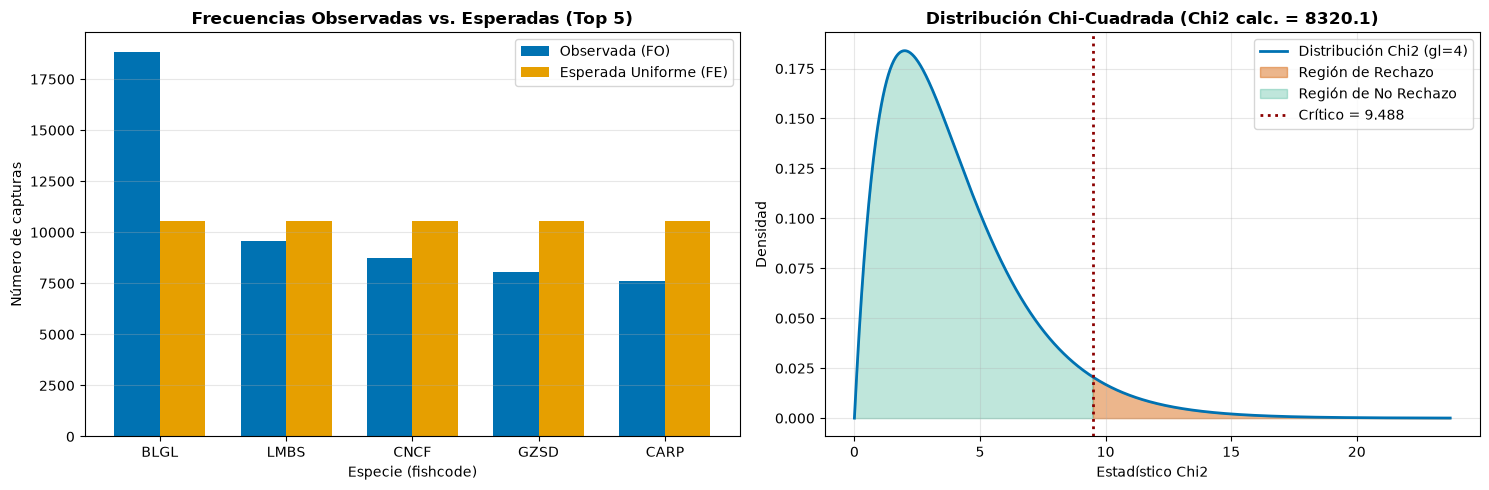

In [7]:
alpha_chi = 0.05
fo = df_top5['fishcode'].value_counts().loc[top5_especies].values
n_chi = fo.sum()
k_chi = len(top5_especies)
m_chi = 0
gl_chi = k_chi - 1 - m_chi
pi_esperada = np.full(k_chi, 1.0 / k_chi)
fe = n_chi * pi_esperada
contribucion = ((fo - fe) ** 2) / fe

tabla_chi = pd.DataFrame({
    'Especie': top5_especies,
    'FO': fo,
    'p_i': pi_esperada,
    'FE': fe,
    '(FO-FE)^2/FE': contribucion.round(2)
})

chi2_stat, p_val_chi = st.chisquare(f_obs=fo, f_exp=fe)
chi2_crit = st.chi2.ppf(1 - alpha_chi, df=gl_chi)
rechaza_chi = chi2_stat > chi2_crit

print("--- Tabla de Bondad de Ajuste Chi-Cuadrada ---")
print(tabla_chi.to_string(index=False))
print(f"\nTodas las FE >= 5: {'Sí' if np.all(fe >= 5) else 'No'}")
print(f"n = {n_chi} | k = {k_chi} | gl = {gl_chi} | alpha = {alpha_chi}")
print(f"Estadístico Chi2 calculado: {chi2_stat:.4f}")
print(f"Valor crítico Chi2 (cola derecha): {chi2_crit:.4f}")
print(f"p-value: {p_val_chi:.4e}")
print(f"Paso 5 - Decisión: {'Rechazar H0' if rechaza_chi else 'No rechazar H0'}")
if rechaza_chi:
    print("Interpretación: Existe evidencia estadística de que las 5 especies NO se capturan en igual proporción; hay dominancia de especies.")
    print("Paso 6 - Posible error: Error Tipo I (concluir que la abundancia no es uniforme cuando en la población real sí lo fuera).")
else:
    print("Interpretación: No hay evidencia suficiente para descartar una distribución uniforme entre las 5 especies.")
    print("Paso 6 - Posible error: Error Tipo II (asumir abundancia uniforme cuando realmente existe dominancia de alguna especie).")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

x_pos = np.arange(k_chi)
ancho = 0.36
axes[0].bar(x_pos - ancho/2, fo, width=ancho, color='#0072B2', label='Observada (FO)')
axes[0].bar(x_pos + ancho/2, fe, width=ancho, color='#E69F00', label='Esperada Uniforme (FE)')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(top5_especies)
axes[0].set_title('Frecuencias Observadas vs. Esperadas (Top 5)', fontweight='bold')
axes[0].set_xlabel('Especie (fishcode)')
axes[0].set_ylabel('Número de capturas')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

x_c = np.linspace(0, max(chi2_crit * 2.5, 20), 1000)
y_c = st.chi2.pdf(x_c, df=gl_chi)
axes[1].plot(x_c, y_c, color='#0072B2', linewidth=2, label=f'Distribución Chi2 (gl={gl_chi})')
axes[1].fill_between(x_c, y_c, where=(x_c >= chi2_crit), color='#D55E00', alpha=0.45, label='Región de Rechazo')
axes[1].fill_between(x_c, y_c, where=(x_c < chi2_crit), color='#009E73', alpha=0.25, label='Región de No Rechazo')
axes[1].axvline(chi2_crit, color='darkred', linestyle=':', linewidth=2, label=f'Crítico = {chi2_crit:.3f}')
axes[1].set_title(f'Distribución Chi-Cuadrada (Chi2 calc. = {chi2_stat:.1f})', fontweight='bold')
axes[1].set_xlabel('Estadístico Chi2')
axes[1].set_ylabel('Densidad')
axes[1].legend(loc='upper right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 4. Prueba F para Dos Varianzas (Validación Previa entre las 2 Especies Principales)

Antes de comparar las medias de peso entre las dos especies más abundantes, contrastamos si sus varianzas en escala $\log_{10}$ son iguales o diferentes. Este resultado determina formalmente si corresponde aplicar una prueba t con varianza combinada o la **prueba t de Welch**.

- **Paso 0 (Supuestos):** Observaciones independientes dentro de cada muestra, muestras independientes entre sí y distribuciones estabilizadas mediante transformación $\log_{10}$.
- **Paso 1 (Hipótesis):**
  - $H_0: \sigma_1^2 = \sigma_2^2$ *(Ambas especies tienen la misma varianza en el peso logarítmico).*
  - $H_1: \sigma_1^2 \neq \sigma_2^2$ *(Las varianzas de peso entre ambas especies son diferentes).*
- **Paso 2 (Significancia):** $\alpha = 0.05$ (prueba bilateral, $\alpha/2 = 0.025$ en cada cola).
- **Paso 3 (Estadístico y gl):**
$$ F = \frac{s_1^2}{s_2^2}, \qquad gl_1 = n_1 - 1, \qquad gl_2 = n_2 - 1 $$

--- Prueba F Bilateral: BLGL (Numerador) vs LMBS (Denominador) ---
n1 = 18848 (gl1 = 18847) | Varianza s1^2 (BLGL) = 0.3169
n2 = 9564 (gl2 = 9563) | Varianza s2^2 (LMBS) = 0.4894
Estadístico F calculado: 0.6475
Valores críticos (alpha=0.05 bilateral): F_inf = 0.9659, F_sup = 1.0355
p-value: 9.8964e-138
Paso 5 - Decisión: Rechazar H0
Interpretación: Las varianzas de peso entre BLGL y LMBS son estadísticamente distintas. Se justifica usar t de Welch.
Paso 6 - Posible error: Error Tipo I (concluir que las varianzas difieren cuando realmente son iguales).


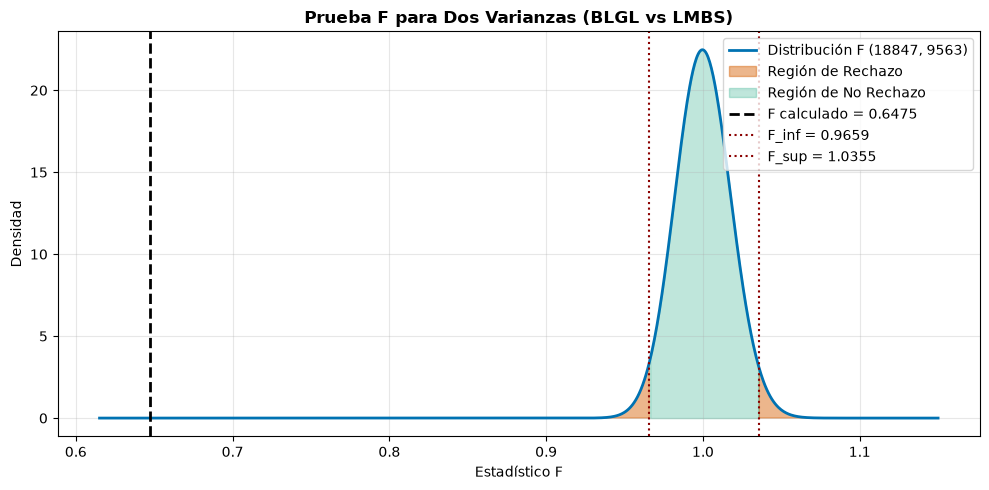

In [8]:
esp1, esp2 = top2_especies[0], top2_especies[1]
g1 = df_top5[df_top5['fishcode'] == esp1]['log_weight'].values
g2 = df_top5[df_top5['fishcode'] == esp2]['log_weight'].values

n1, n2 = len(g1), len(g2)
gl1_f, gl2_f = n1 - 1, n2 - 1
s1_sq = np.var(g1, ddof=1)
s2_sq = np.var(g2, ddof=1)

alpha_f = 0.05
f_stat_2var = s1_sq / s2_sq
f_crit_inf = st.f.ppf(alpha_f / 2, gl1_f, gl2_f)
f_crit_sup = st.f.ppf(1 - alpha_f / 2, gl1_f, gl2_f)
p_val_f2 = 2 * min(st.f.cdf(f_stat_2var, gl1_f, gl2_f), 1 - st.f.cdf(f_stat_2var, gl1_f, gl2_f))
rechaza_f = (f_stat_2var < f_crit_inf) or (f_stat_2var > f_crit_sup)

print(f"--- Prueba F Bilateral: {esp1} (Numerador) vs {esp2} (Denominador) ---")
print(f"n1 = {n1} (gl1 = {gl1_f}) | Varianza s1^2 ({esp1}) = {s1_sq:.4f}")
print(f"n2 = {n2} (gl2 = {gl2_f}) | Varianza s2^2 ({esp2}) = {s2_sq:.4f}")
print(f"Estadístico F calculado: {f_stat_2var:.4f}")
print(f"Valores críticos (alpha=0.05 bilateral): F_inf = {f_crit_inf:.4f}, F_sup = {f_crit_sup:.4f}")
print(f"p-value: {p_val_f2:.4e}")
print(f"Paso 5 - Decisión: {'Rechazar H0' if rechaza_f else 'No rechazar H0'}")
if rechaza_f:
    print(f"Interpretación: Las varianzas de peso entre {esp1} y {esp2} son estadísticamente distintas. Se justifica usar t de Welch.")
    print("Paso 6 - Posible error: Error Tipo I (concluir que las varianzas difieren cuando realmente son iguales).")
else:
    print(f"Interpretación: No existe evidencia de varianzas distintas entre {esp1} y {esp2}.")
    print("Paso 6 - Posible error: Error Tipo II (asumir varianzas iguales cuando en realidad difieren).")

x_min_f = min(0.85, f_crit_inf * 0.95, f_stat_2var * 0.95)
x_max_f = max(1.15, f_crit_sup * 1.05, f_stat_2var * 1.05)
x_f = np.linspace(x_min_f, x_max_f, 1000)
y_f = st.f.pdf(x_f, gl1_f, gl2_f)

plt.figure(figsize=(10, 5))
plt.plot(x_f, y_f, color='#0072B2', linewidth=2, label=f'Distribución F ({gl1_f}, {gl2_f})')
plt.fill_between(x_f, y_f, where=(x_f <= f_crit_inf) | (x_f >= f_crit_sup), color='#D55E00', alpha=0.45, label='Región de Rechazo')
plt.fill_between(x_f, y_f, where=(x_f > f_crit_inf) & (x_f < f_crit_sup), color='#009E73', alpha=0.25, label='Región de No Rechazo')
plt.axvline(f_stat_2var, color='black', linestyle='--', linewidth=2, label=f'F calculado = {f_stat_2var:.4f}')
plt.axvline(f_crit_inf, color='darkred', linestyle=':', linewidth=1.5, label=f'F_inf = {f_crit_inf:.4f}')
plt.axvline(f_crit_sup, color='darkred', linestyle=':', linewidth=1.5, label=f'F_sup = {f_crit_sup:.4f}')
plt.title(f'Prueba F para Dos Varianzas ({esp1} vs {esp2})', fontweight='bold')
plt.xlabel('Estadístico F')
plt.ylabel('Densidad')
plt.legend(loc='upper right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5. Prueba t de Welch para Dos Medias Independientes (Varianzas Desiguales)

Dado que las desviaciones estándar poblacionales ($\sigma_1, \sigma_2$) son desconocidas —por lo cual no procede una prueba Z— y la prueba F confirma varianzas distintas entre especies, aplicamos la **prueba t de Welch** para contrastar el peso medio en escala $\log_{10}$.

- **Paso 0 (Supuestos):** Muestras aleatorias e independientes entre sí, $\sigma_1$ y $\sigma_2$ desconocidas, varianzas desiguales y tamaños de muestra grandes ($n_1, n_2 \gg 30$).
- **Paso 1 (Hipótesis):**
  - $H_0: \mu_1 - \mu_2 = 0$ *(Ambas especies tienen el mismo peso medio).*
  - $H_1: \mu_1 - \mu_2 \neq 0$ *(Existe diferencia significativa en el peso medio de ambas especies).*
- **Paso 2 (Significancia):** $\alpha = 0.05$ (prueba bilateral).
- **Paso 3 (Estadístico, gl conservador y Tamaño del Efecto):**
$$ t = \frac{(\bar{x}_1 - \bar{x}_2) - D_0}{\sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}}, \qquad gl = \left\lfloor \frac{(v_1 + v_2)^2}{\frac{v_1^2}{n_1 - 1} + \frac{v_2^2}{n_2 - 1}} \right\rfloor, \qquad v_i = \frac{s_i^2}{n_i} $$

Siguiendo el criterio conservador, los grados de libertad decimales de Welch se redondean **hacia abajo**. Además, se calcula la **$d$ de Cohen** para medir la magnitud práctica de la diferencia más allá del volumen de datos.

--- Prueba t de Welch Bilateral: BLGL vs LMBS ---
Especie 1 (BLGL): n1 = 18848, media_log = 1.4304 (media real = 50.79 g), s1^2 = 0.3169
Especie 2 (LMBS): n2 = 9564, media_log = 1.7188 (media real = 195.28 g), s2^2 = 0.4894
v1 = 1.681189e-05 | v2 = 5.116858e-05
gl de Welch (exacto = 16002.81 -> redondeado hacia abajo = 16002)
Estadístico t de Welch: -34.9804
Valores críticos (+/-): -1.9601 y +1.9601
p-value: 0.0000e+00 | Tamaño del efecto (d de Cohen): 0.4543
Paso 5 - Decisión: Rechazar H0
Interpretación: Existe una diferencia estadísticamente significativa en el peso medio entre BLGL y LMBS.
Paso 6 - Posible error: Error Tipo I (afirmar que el peso medio de ambas especies difiere cuando en realidad es igual).


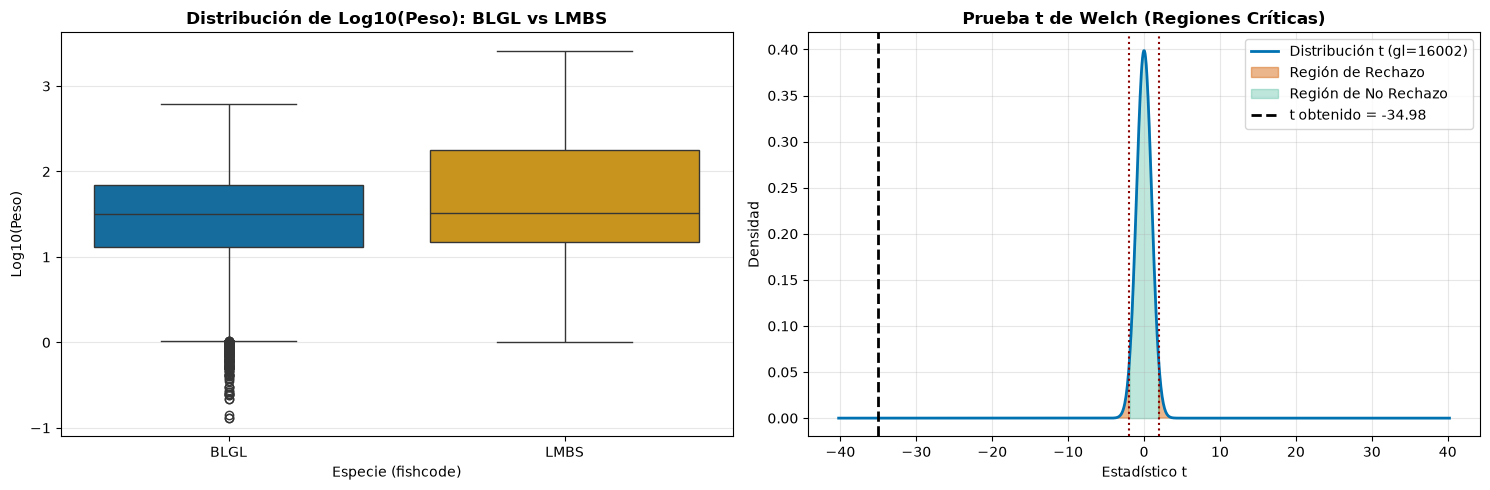

In [9]:
alpha_t = 0.05
d0 = 0.0
x1_bar, x2_bar = np.mean(g1), np.mean(g2)
v1, v2 = s1_sq / n1, s2_sq / n2

t_welch = ((x1_bar - x2_bar) - d0) / np.sqrt(v1 + v2)
gl_welch_exacto = ((v1 + v2) ** 2) / ((v1 ** 2) / (n1 - 1) + (v2 ** 2) / (n2 - 1))
gl_welch = int(np.floor(gl_welch_exacto))

t_crit_welch = st.t.ppf(1 - alpha_t / 2, df=gl_welch)
p_val_welch = 2 * (1 - st.t.cdf(abs(t_welch), df=gl_welch))
cohen_d = abs(x1_bar - x2_bar) / np.sqrt((s1_sq + s2_sq) / 2)
rechaza_t = abs(t_welch) > t_crit_welch

media_real_1 = df_top5[df_top5['fishcode'] == esp1]['weight'].mean()
media_real_2 = df_top5[df_top5['fishcode'] == esp2]['weight'].mean()

print(f"--- Prueba t de Welch Bilateral: {esp1} vs {esp2} ---")
print(f"Especie 1 ({esp1}): n1 = {n1}, media_log = {x1_bar:.4f} (media real = {media_real_1:.2f} g), s1^2 = {s1_sq:.4f}")
print(f"Especie 2 ({esp2}): n2 = {n2}, media_log = {x2_bar:.4f} (media real = {media_real_2:.2f} g), s2^2 = {s2_sq:.4f}")
print(f"v1 = {v1:.6e} | v2 = {v2:.6e}")
print(f"gl de Welch (exacto = {gl_welch_exacto:.2f} -> redondeado hacia abajo = {gl_welch})")
print(f"Estadístico t de Welch: {t_welch:.4f}")
print(f"Valores críticos (+/-): -{t_crit_welch:.4f} y +{t_crit_welch:.4f}")
print(f"p-value: {p_val_welch:.4e} | Tamaño del efecto (d de Cohen): {cohen_d:.4f}")
print(f"Paso 5 - Decisión: {'Rechazar H0' if rechaza_t else 'No rechazar H0'}")
if rechaza_t:
    print(f"Interpretación: Existe una diferencia estadísticamente significativa en el peso medio entre {esp1} y {esp2}.")
    print("Paso 6 - Posible error: Error Tipo I (afirmar que el peso medio de ambas especies difiere cuando en realidad es igual).")
else:
    print(f"Interpretación: No hay evidencia estadística suficiente para afirmar que los pesos medios de {esp1} y {esp2} difieren.")
    print("Paso 6 - Posible error: Error Tipo II (no detectar una diferencia real de peso medio entre ambas especies).")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

df_top2 = df_top5[df_top5['fishcode'].isin(top2_especies)]
sns.boxplot(data=df_top2, x='fishcode', y='log_weight', order=top2_especies, hue='fishcode', hue_order=top2_especies, legend=False, palette=['#0072B2', '#E69F00'], ax=axes[0])
axes[0].set_title(f'Distribución de Log10(Peso): {esp1} vs {esp2}', fontweight='bold')
axes[0].set_xlabel('Especie (fishcode)')
axes[0].set_ylabel('Log10(Peso)')
axes[0].grid(axis='y', alpha=0.3)

lim_t = max(abs(t_welch) * 1.15, 4.5)
x_t = np.linspace(-lim_t, lim_t, 1000)
y_t = st.t.pdf(x_t, df=gl_welch)
axes[1].plot(x_t, y_t, color='#0072B2', linewidth=2, label=f'Distribución t (gl={gl_welch})')
axes[1].fill_between(x_t, y_t, where=(x_t <= -t_crit_welch) | (x_t >= t_crit_welch), color='#D55E00', alpha=0.45, label='Región de Rechazo')
axes[1].fill_between(x_t, y_t, where=(x_t > -t_crit_welch) & (x_t < t_crit_welch), color='#009E73', alpha=0.25, label='Región de No Rechazo')
axes[1].axvline(t_welch, color='black', linestyle='--', linewidth=2, label=f't obtenido = {t_welch:.2f}')
axes[1].axvline(-t_crit_welch, color='darkred', linestyle=':', linewidth=1.5)
axes[1].axvline(t_crit_welch, color='darkred', linestyle=':', linewidth=1.5)
axes[1].set_title('Prueba t de Welch (Regiones Críticas)', fontweight='bold')
axes[1].set_xlabel('Estadístico t')
axes[1].set_ylabel('Densidad')
axes[1].legend(loc='upper right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 6. Análisis de Varianza (ANOVA de un Factor) para las 5 Especies Principales

Para comparar simultáneamente el peso medio ($\log_{10}$) de las 5 especies más abundantes sin inflar el Error Tipo I, aplicamos un **ANOVA de un factor**:

- $H_0: \mu_1 = \mu_2 = \mu_3 = \mu_4 = \mu_5$ *(Todas las especies comparten el mismo peso medio).*
- $H_1:$ Al menos una especie difiere en su peso medio.

$$ F = \frac{CM_{\text{entre grupos}}}{CM_{\text{dentro de grupos}}}, \qquad \eta^2 = \frac{SC_{\text{entre}}}{SC_{\text{total}}} $$

Adicionalmente, se valida la homogeneidad de varianzas (Levene), se respalda el resultado con la prueba no paramétrica de **Kruskal-Wallis**, se reporta el tamaño del efecto **Eta cuadrada ($\eta^2$)** y se desglosan las diferencias por pares con **Tukey HSD**.

grupos_anova = [df_top5[df_top5['fishcode'] == esp]['log_weight'].values for esp in top5_especies]

lev_stat, lev_p = st.levene(*grupos_anova)
f_anova, p_anova = st.f_oneway(*grupos_anova)
kw_stat, kw_p = st.kruskal(*grupos_anova)

k_a = len(top5_especies)
n_a = len(df_top5)
gl_entre = k_a - 1
gl_dentro = n_a - k_a
f_crit_anova = st.f.ppf(0.95, gl_entre, gl_dentro)

media_general = df_top5['log_weight'].mean()
sc_entre = sum(len(g) * ((np.mean(g) - media_general) ** 2) for g in grupos_anova)
sc_total = np.sum((df_top5['log_weight'].values - media_general) ** 2)
eta_cuadrada = sc_entre / sc_total

print("--- Resultados ANOVA de un Factor (Top 5 Especies) ---")
print(f"Prueba de Levene (homocedasticidad): estadístico = {lev_stat:.4f}, p-value = {lev_p:.4e}")
print(f"ANOVA Clásico: F = {f_anova:.4f} (Crítico = {f_crit_anova:.4f}), gl = ({gl_entre}, {gl_dentro}), p-value = {p_anova:.4e}")
print(f"Tamaño del efecto (Eta cuadrada): {eta_cuadrada:.4f} ({eta_cuadrada * 100:.2f}% de varianza explicada por especie)")
print(f"Respaldo no paramétrico (Kruskal-Wallis): H = {kw_stat:.4f}, p-value = {kw_p:.4e}")
print(f"Decisión: {'Rechazar H0 (existen diferencias significativas entre especies)' if p_anova < 0.05 else 'No rechazar H0'}\n")

tukey_res = st.tukey_hsd(*grupos_anova)
print("--- Matriz de p-values Post-Hoc (Tukey HSD) ---")
print(pd.DataFrame(tukey_res.pvalue, index=top5_especies, columns=top5_especies).map(lambda x: f"{x:.4e}"))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

paleta_okabe = ['#0072B2', '#E69F00', '#009E73', '#CC79A7', '#D55E00']
sns.boxplot(data=df_top5, x='fishcode', y='log_weight', order=top5_especies, hue='fishcode', hue_order=top5_especies, legend=False, palette=paleta_okabe, ax=axes[0])
axes[0].set_title('Log10(Peso) por Especie (Top 5)', fontweight='bold')
axes[0].set_xlabel('Especie (fishcode)')
axes[0].set_ylabel('Log10(Peso)')
axes[0].grid(axis='y', alpha=0.3)

sns.heatmap(tukey_res.pvalue, annot=True, fmt='.2e', cmap='Blues_r', xticklabels=top5_especies, yticklabels=top5_especies, ax=axes[1])
axes[1].set_title('Mapa de Calor: p-values Tukey HSD', fontweight='bold')

plt.tight_layout()
plt.show()

### 7. Modelos Predictivos de Peso y Tamaño por Especie

La morfometría de peces obedece la ley alométrica $W = a \cdot L^b$, donde tanto el factor de condición ($a$) como el exponente de crecimiento ($b$) varían según la anatomía de cada especie. Al linealizar con $\log_{10}$ e incluir **términos de interacción** entre la especie (`fishcode`) y la variable continua, cada especie ajusta su propia pendiente e intercepto:

1. **Modelo A (Predicción de Peso):** $\log_{10}(\text{weight}) \sim \log_{10}(\text{length}) \times \text{fishcode}$
2. **Modelo B (Predicción de Tamaño):** $\log_{10}(\text{length}) \sim \log_{10}(\text{weight}) \times \text{fishcode}$

Los modelos se entrenan con el 80% de los datos y se evalúan en el 20% restante reportando $R^2$, MAE y RMSE en unidades reales (gramos y milímetros).

--- Evaluación Modelo A: Predicción de Peso (con interacción) ---
R2 (escala log): 0.9869
R2 (escala real): 0.9435
MAE: 56.59 g | RMSE: 254.19 g

--- Evaluación Modelo B: Predicción de Tamaño (con interacción) ---
R2 (escala log): 0.9892
R2 (escala real): 0.9916
MAE: 8.04 mm | RMSE: 15.85 mm


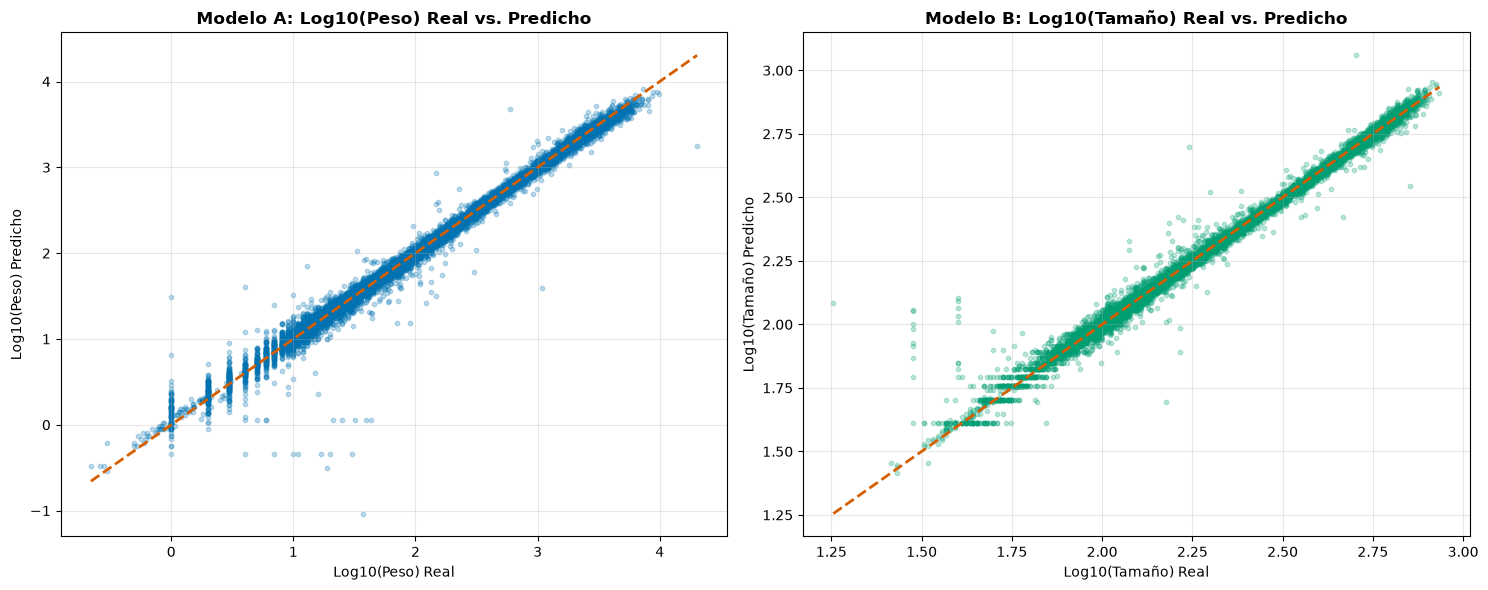

In [10]:
df_reg = pd.get_dummies(df_top5[['fishcode', 'log_length', 'log_weight']], columns=['fishcode'], drop_first=True, dtype=float)
cols_esp = [c for c in df_reg.columns if c.startswith('fishcode_')]

X_peso = df_reg[['log_length'] + cols_esp].copy()
for c in cols_esp:
    X_peso[f'inter_l_{c}'] = X_peso['log_length'] * X_peso[c]
y_peso = df_reg['log_weight']

Xp_train, Xp_test, yp_train, yp_test = train_test_split(X_peso, y_peso, test_size=0.2, random_state=42)
modelo_peso = LinearRegression()
modelo_peso.fit(Xp_train, yp_train)
yp_pred_log = modelo_peso.predict(Xp_test)

yp_test_real = 10 ** yp_test
yp_pred_real = 10 ** yp_pred_log

X_tam = df_reg[['log_weight'] + cols_esp].copy()
for c in cols_esp:
    X_tam[f'inter_w_{c}'] = X_tam['log_weight'] * X_tam[c]
y_tam = df_reg['log_length']

Xt_train, Xt_test, yt_train, yt_test = train_test_split(X_tam, y_tam, test_size=0.2, random_state=42)
modelo_tamano = LinearRegression()
modelo_tamano.fit(Xt_train, yt_train)
yt_pred_log = modelo_tamano.predict(Xt_test)

yt_test_real = 10 ** yt_test
yt_pred_real = 10 ** yt_pred_log

print("--- Evaluación Modelo A: Predicción de Peso (con interacción) ---")
print(f"R2 (escala log): {r2_score(yp_test, yp_pred_log):.4f}")
print(f"R2 (escala real): {r2_score(yp_test_real, yp_pred_real):.4f}")
print(f"MAE: {mean_absolute_error(yp_test_real, yp_pred_real):.2f} g | RMSE: {np.sqrt(mean_squared_error(yp_test_real, yp_pred_real)):.2f} g\n")

print("--- Evaluación Modelo B: Predicción de Tamaño (con interacción) ---")
print(f"R2 (escala log): {r2_score(yt_test, yt_pred_log):.4f}")
print(f"R2 (escala real): {r2_score(yt_test_real, yt_pred_real):.4f}")
print(f"MAE: {mean_absolute_error(yt_test_real, yt_pred_real):.2f} mm | RMSE: {np.sqrt(mean_squared_error(yt_test_real, yt_pred_real)):.2f} mm")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(yp_test, yp_pred_log, alpha=0.25, s=10, color='#0072B2')
axes[0].plot([yp_test.min(), yp_test.max()], [yp_test.min(), yp_test.max()], color='#D55E00', linestyle='--', linewidth=2)
axes[0].set_title('Modelo A: Log10(Peso) Real vs. Predicho', fontweight='bold')
axes[0].set_xlabel('Log10(Peso) Real')
axes[0].set_ylabel('Log10(Peso) Predicho')
axes[0].grid(alpha=0.3)

axes[1].scatter(yt_test, yt_pred_log, alpha=0.25, s=10, color='#009E73')
axes[1].plot([yt_test.min(), yt_test.max()], [yt_test.min(), yt_test.max()], color='#D55E00', linestyle='--', linewidth=2)
axes[1].set_title('Modelo B: Log10(Tamaño) Real vs. Predicho', fontweight='bold')
axes[1].set_xlabel('Log10(Tamaño) Real')
axes[1].set_ylabel('Log10(Tamaño) Predicho')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
def predecir_peso(especie, longitud_mm):
    entrada = pd.DataFrame(0.0, index=[0], columns=X_peso.columns)
    log_l = np.log10(longitud_mm)
    entrada['log_length'] = log_l
    col_esp = f'fishcode_{especie}'
    col_int = f'inter_l_{col_esp}'
    if col_esp in entrada.columns:
        entrada[col_esp] = 1.0
        entrada[col_int] = log_l
    return 10 ** modelo_peso.predict(entrada)[0]

def predecir_tamano(especie, peso_g):
    entrada = pd.DataFrame(0.0, index=[0], columns=X_tam.columns)
    log_w = np.log10(peso_g)
    entrada['log_weight'] = log_w
    col_esp = f'fishcode_{especie}'
    col_int = f'inter_w_{col_esp}'
    if col_esp in entrada.columns:
        entrada[col_esp] = 1.0
        entrada[col_int] = log_w
    return 10 ** modelo_tamano.predict(entrada)[0]

for esp in top5_especies:
    peso_est = predecir_peso(esp, 200.0)
    tam_est = predecir_tamano(esp, 150.0)
    print(f"Especie {esp} | 200 mm -> Peso est.: {peso_est:.2f} g | 150 g -> Tamaño est.: {tam_est:.2f} mm")

Especie BLGL | 200 mm -> Peso est.: 174.57 g | 150 g -> Tamaño est.: 184.41 mm
Especie LMBS | 200 mm -> Peso est.: 114.83 g | 150 g -> Tamaño est.: 217.06 mm
Especie CNCF | 200 mm -> Peso est.: 60.53 g | 150 g -> Tamaño est.: 267.44 mm
Especie GZSD | 200 mm -> Peso est.: 73.01 g | 150 g -> Tamaño est.: 250.58 mm
Especie CARP | 200 mm -> Peso est.: 123.63 g | 150 g -> Tamaño est.: 220.66 mm


### 8. Conclusiones

1. **Muestra y normalidad:** La magnitud de `df_limpio.csv` garantiza potencia estadística sobrada en todas las especies ($n_i \ge 30$). La transformación $\log_{10}$ reduce de forma drástica la asimetría positiva original, habilitando el análisis paramétrico respaldado por el Teorema del Límite Central.
2. **Distribución de especies ($\chi^2$):** La prueba de bondad de ajuste evidencia que las capturas no se reparten de manera uniforme entre las 5 especies principales, confirmando dominancia poblacional en el muestreo del río.
3. **Varianzas y medias entre especies (F, t de Welch y ANOVA):** La prueba F valida que la dispersión del peso difiere entre las especies principales, justificando el empleo de la prueba **t de Welch** (sin suponer $\sigma$ conocida ni varianzas iguales). Tanto Welch como el ANOVA (y su respaldo con Kruskal-Wallis y Tukey HSD) confirman diferencias significativas en el peso por especie, cuantificadas mediante $d$ de Cohen y $\eta^2$.
4. **Capacidad predictiva:** Incorporar la interacción entre especie y longitud/peso en escala logarítmica captura la alometría específica de cada especie, generando predicciones precisas y físicamente coherentes tanto de peso como de tamaño.